# Bean Leaf Disease Classification — MobileNet (deployable version)

Classifies bean leaf photos into **angular leaf spot**, **bean rust** or **healthy**, and exports the model to **TensorFlow Lite** for an offline Android app.

**What changed vs. the original notebook**
- Validation/test sets are no longer shuffled → confusion matrix and classification report now match `model.evaluate`
- Augmentation is applied once (training pipeline only), so the saved model has no random layers and exports cleanly
- MobileNet's own preprocessing (pixels scaled to [-1, 1]) is built into the model → the app feeds raw RGB pixels (0–255)
- `GlobalAveragePooling2D` instead of `Flatten`; input size 224 (matches the ImageNet weights)
- Two-stage training: frozen backbone with Adam, then fine-tuning of the top layers with a small learning rate
- Best model is saved to disk; `predict()` bug fixed; duplicate/unused imports removed
- TFLite export + check that the `.tflite` model gives the same accuracy as Keras

**Expected folder layout** (next to this notebook):
```
train/       angular_leaf_spot/  bean_rust/  healthy/
validation/  angular_leaf_spot/  bean_rust/  healthy/
test/        angular_leaf_spot/  bean_rust/  healthy/
```

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report

print("TensorFlow", tf.__version__)
tf.keras.utils.set_random_seed(123)

TensorFlow 2.17.0


## 1. Settings

In [2]:
DATA_DIR   = "."          # folder that contains train/, validation/, test/
IMAGE_SIZE = 224          # MobileNet ImageNet weights are trained at 224
BATCH_SIZE = 32
EPOCHS_HEAD = 15          # stage 1: train only the classifier head
EPOCHS_FINE = 20          # stage 2: fine-tune the top of MobileNet
FINE_TUNE_LAYERS = 30     # how many of MobileNet's last layers to unfreeze

OUT_DIR = "export"
os.makedirs(OUT_DIR, exist_ok=True)

## 2. Load the data
Only the training set is shuffled. Val/test keep a fixed order so predictions and labels line up.

In [3]:
def load(split, shuffle, batch_size=BATCH_SIZE):
    return keras.utils.image_dataset_from_directory(
        os.path.join(DATA_DIR, split),
        image_size=(IMAGE_SIZE, IMAGE_SIZE),
        batch_size=batch_size,
        shuffle=shuffle,
        seed=123,
    )

# Training images are loaded unbatched so they can be shuffled individually every epoch
train_raw = load("train", shuffle=True, batch_size=None)
val_raw   = load("validation", shuffle=False)
test_raw  = load("test", shuffle=False)

class_names = train_raw.class_names
NUM_CLASSES = len(class_names)
print(class_names)

Found 1034 files belonging to 3 classes.
Found 133 files belonging to 3 classes.
Found 128 files belonging to 3 classes.
['angular_leaf_spot', 'bean_rust', 'healthy']


### Sample training images

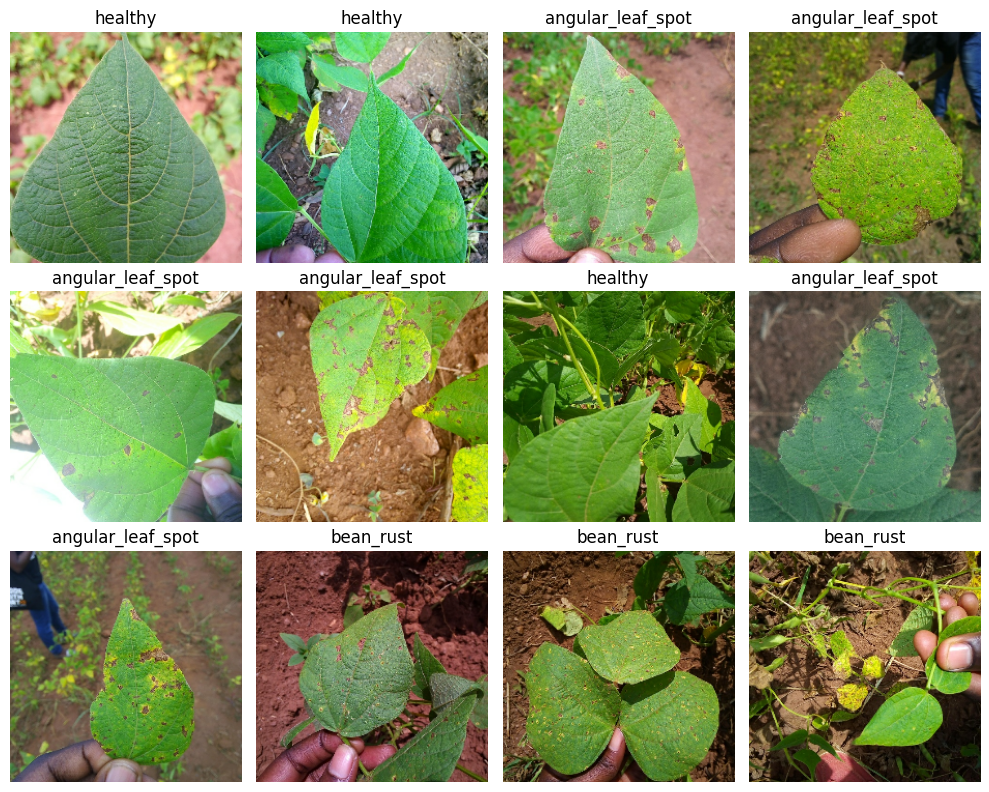

In [4]:
plt.figure(figsize=(10, 8))
for images, labels in train_raw.batch(12).take(1):
    for i in range(len(images)):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.tight_layout()

## 3. Data augmentation (training set only)
Applied in the input pipeline, not inside the model — so the exported model stays deterministic.

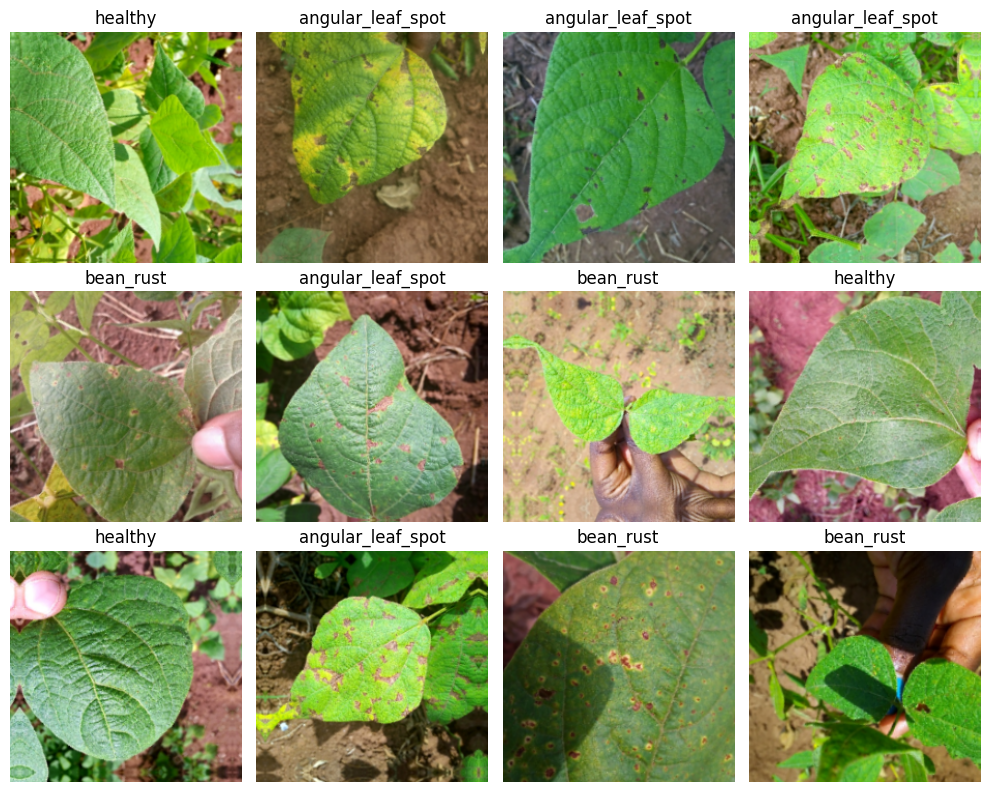

In [5]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),   # helps with varying field light
], name="augmentation")

AUTOTUNE = tf.data.AUTOTUNE
train_ds = (train_raw.cache()
            .shuffle(2000, reshuffle_each_iteration=True)   # shuffle single images, new order every epoch
            .batch(BATCH_SIZE)
            .map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
            .prefetch(AUTOTUNE))
val_ds  = val_raw.cache().prefetch(AUTOTUNE)
test_ds = test_raw.cache().prefetch(AUTOTUNE)

plt.figure(figsize=(10, 8))
for images, labels in train_ds.take(1):
    for i in range(min(12, len(images))):          # last batch can be smaller than 12
        plt.subplot(3, 4, i + 1)
        plt.imshow(np.clip(images[i].numpy(), 0, 255).astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.tight_layout()

## 4. Build the model
Input = raw RGB pixels 0–255. The `Rescaling` layer does MobileNet's preprocessing (`x / 127.5 - 1`), so the Android app doesn't need to normalise anything.

In [6]:
base = keras.applications.MobileNet(
    include_top=False, weights="imagenet", input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
)
base.trainable = False

inputs  = keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3), name="image")
x       = layers.Rescaling(1 / 127.5, offset=-1, name="mobilenet_preprocess")(inputs)
x       = base(x, training=False)          # keeps BatchNorm in inference mode, also while fine-tuning
x       = layers.GlobalAveragePooling2D()(x)
x       = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="probs")(x)
model   = keras.Model(inputs, outputs, name="bean_mobilenet")
model.summary()

Model: "bean_mobilenet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocess            │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_1.00_224 (Functional) │ (None, 7, 7, 1024)     │     3,228,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probs (Dense)                   │ (None, 3)              │         3,075 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,231,939 (12.33 MB)

 Trainable params: 3,075 (12.01 KB)

 Non-trainable params: 3,228,864 (12.32 MB)

## 5. Stage 1 — train the classifier head (backbone frozen)

In [7]:
BEST_PATH = os.path.join(OUT_DIR, "bean_model.keras")

def callbacks():
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(BEST_PATH, monitor="val_loss", save_best_only=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2),
    ]

model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

hist_head = model.fit(train_ds, validation_data=val_ds,
                      epochs=EPOCHS_HEAD, callbacks=callbacks())

Epoch 1/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 17s 380ms/step - accuracy: 0.4215 - loss: 1.3361 - val_accuracy: 0.7218 - val_loss: 0.6022 - learning_rate: 0.0010
Epoch 2/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 12s 348ms/step - accuracy: 0.6919 - loss: 0.7393 - val_accuracy: 0.8271 - val_loss: 0.4274 - learning_rate: 0.0010
Epoch 3/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 12s 352ms/step - accuracy: 0.7495 - loss: 0.6091 - val_accuracy: 0.8647 - val_loss: 0.3982 - learning_rate: 0.0010
Epoch 4/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 12s 343ms/step - accuracy: 0.7946 - loss: 0.5162 - val_accuracy: 0.8872 - val_loss: 0.3294 - learning_rate: 0.0010
Epoch 5/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 12s 343ms/step - accuracy: 0.8051 - loss: 0.4717 - val_accuracy: 0.9023 - val_loss: 0.2937 - learning_rate: 0.0010
Epoch 6/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 14s 419ms/step - accuracy: 0.8487 - loss: 0.4045 - val_accuracy: 0.9023 - val_loss: 0.2781 - learning_rate: 0.0010
Epoch 7/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 13s 371ms/step - accuracy: 0.8487 - loss: 0.

## 6. Stage 2 — fine-tune the top of MobileNet
Small learning rate so the pretrained features are adjusted, not destroyed.

In [8]:
base.trainable = True
for layer in base.layers[:-FINE_TUNE_LAYERS]:
    layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

hist_fine = model.fit(train_ds, validation_data=val_ds,
                      epochs=EPOCHS_FINE, callbacks=callbacks())

model.save(BEST_PATH)   # best weights (restored by EarlyStopping) saved to disk
print("Saved", BEST_PATH)

Epoch 1/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 39s 867ms/step - accuracy: 0.8203 - loss: 0.4380 - val_accuracy: 0.8872 - val_loss: 0.2596 - learning_rate: 1.0000e-05
Epoch 2/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 30s 899ms/step - accuracy: 0.8380 - loss: 0.4206 - val_accuracy: 0.8797 - val_loss: 0.2562 - learning_rate: 1.0000e-05
Epoch 3/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 23s 678ms/step - accuracy: 0.8232 - loss: 0.4282 - val_accuracy: 0.8722 - val_loss: 0.3089 - learning_rate: 1.0000e-05
Epoch 4/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 22s 636ms/step - accuracy: 0.8367 - loss: 0.3878 - val_accuracy: 0.8722 - val_loss: 0.3167 - learning_rate: 1.0000e-05
Epoch 5/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 22s 655ms/step - accuracy: 0.8494 - loss: 0.3798 - val_accuracy: 0.8797 - val_loss: 0.2981 - learning_rate: 3.0000e-06
Epoch 6/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 22s 645ms/step - accuracy: 0.8466 - loss: 0.3923 - val_accuracy: 0.8797 - val_loss: 0.2871 - learning_rate: 3.0000e-06
Epoch 7/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 22s 645ms/step - acc

## 7. Training curves

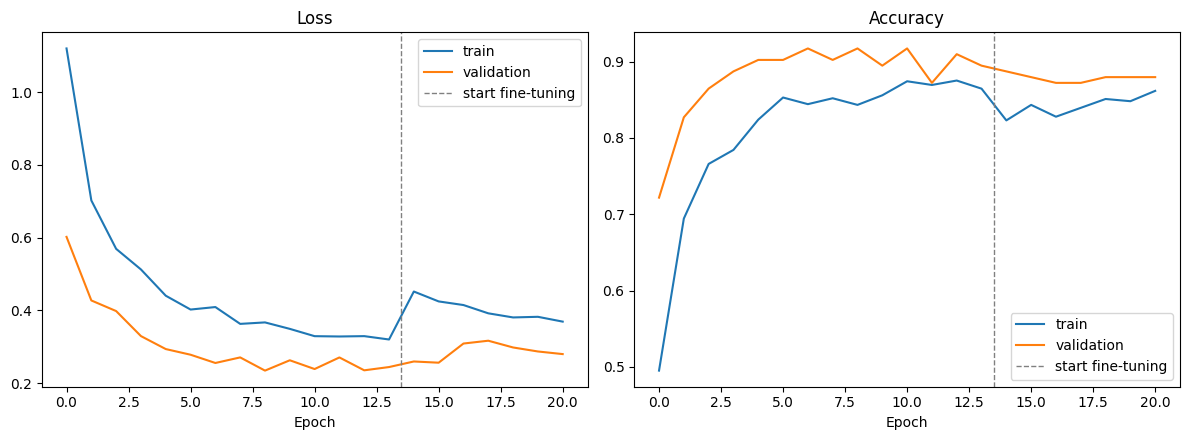

In [9]:
def merge(key):
    return hist_head.history[key] + hist_fine.history[key]

n_head = len(hist_head.history["loss"])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, key, title in [(ax[0], "loss", "Loss"), (ax[1], "accuracy", "Accuracy")]:
    a.plot(merge(key), label="train")
    a.plot(merge("val_" + key), label="validation")
    a.axvline(n_head - 0.5, color="grey", ls="--", lw=1, label="start fine-tuning")
    a.set_title(title); a.set_xlabel("Epoch"); a.legend()
plt.tight_layout()

## 8. Evaluate on the test set
Predictions and labels are collected in the **same** loop, so they always line up.

Test accuracy: 0.8750   loss: 0.2622


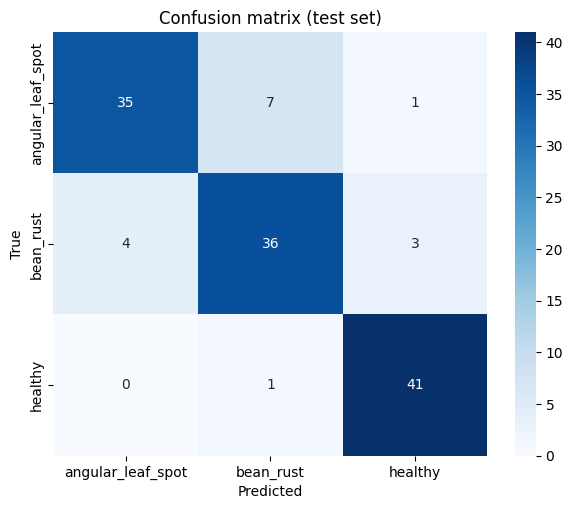

                   precision    recall  f1-score   support

angular_leaf_spot      0.897     0.814     0.854        43
        bean_rust      0.818     0.837     0.828        43
          healthy      0.911     0.976     0.943        42

         accuracy                          0.875       128
        macro avg      0.876     0.876     0.875       128
     weighted avg      0.875     0.875     0.874       128



In [10]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy: {test_acc:.4f}   loss: {test_loss:.4f}")

y_true, y_pred, y_prob = [], [], []
for x, y in test_ds:
    p = model.predict(x, verbose=0)
    y_prob.append(p)
    y_pred.append(p.argmax(axis=1))
    y_true.append(y.numpy())
y_true = np.concatenate(y_true)
y_pred = np.concatenate(y_pred)
y_prob = np.concatenate(y_prob)

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix (test set)")
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

### Example predictions

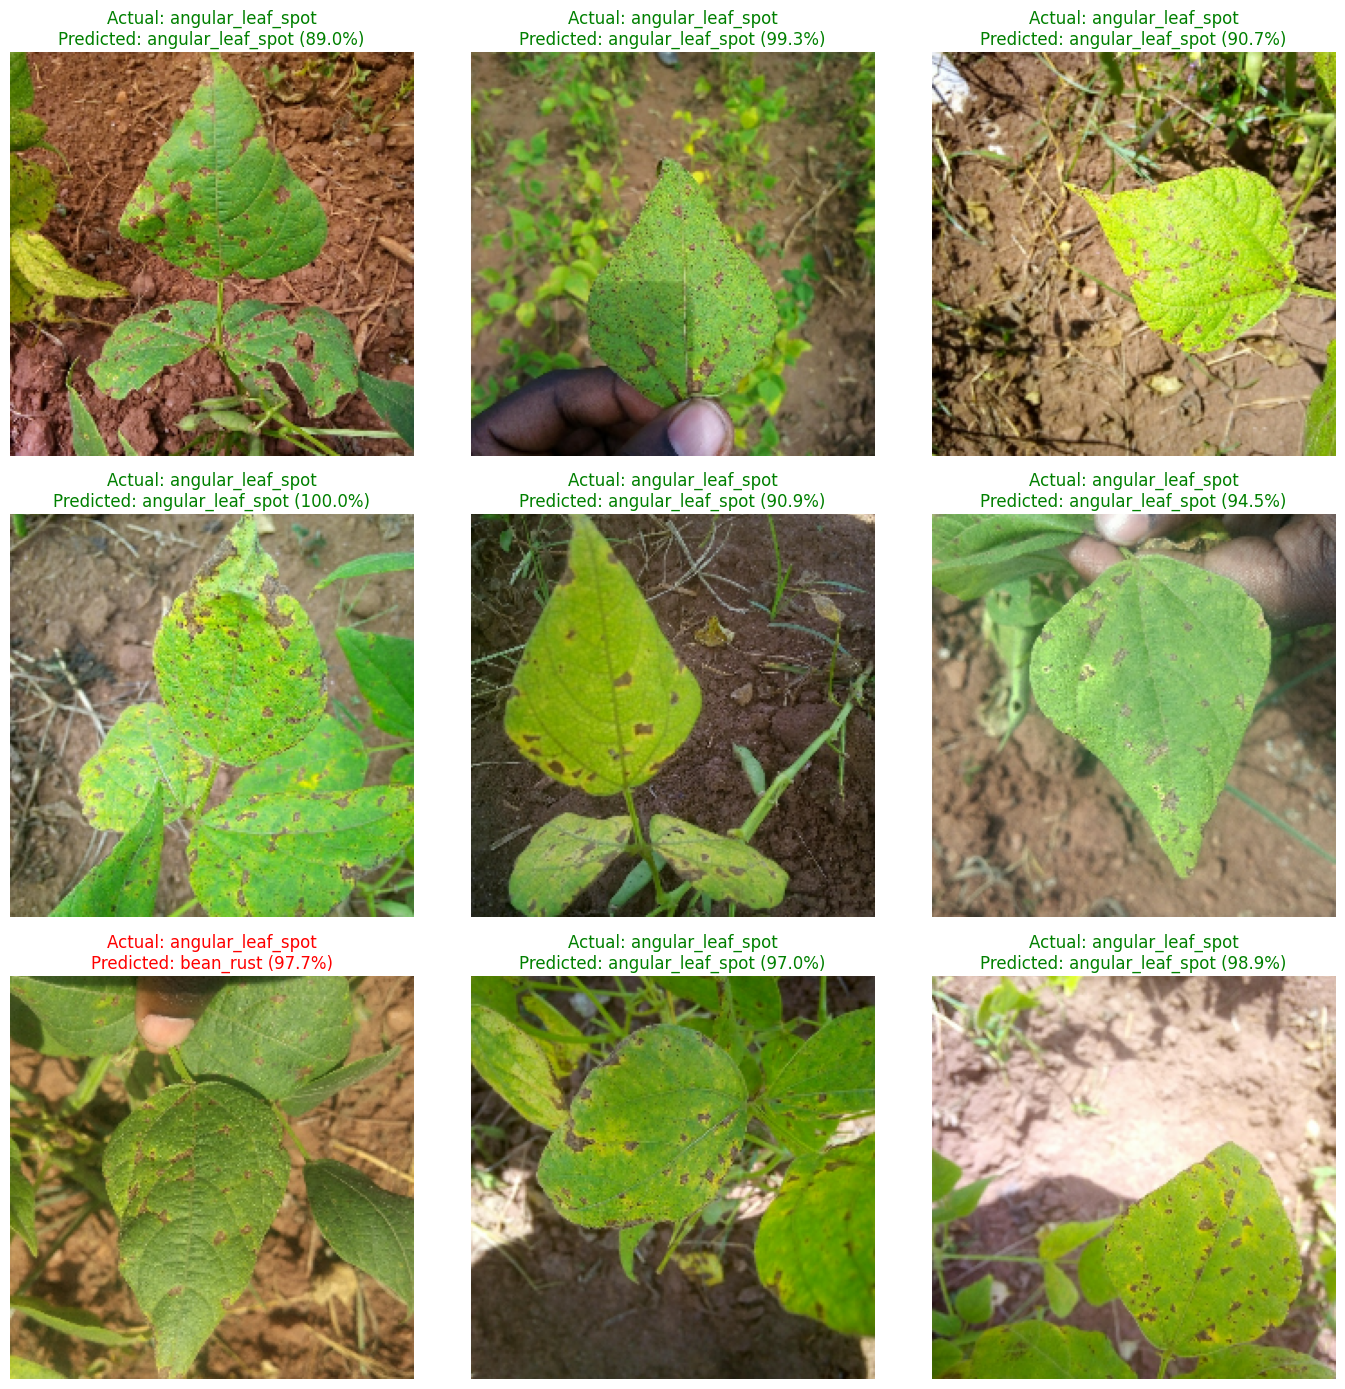

In [11]:
def predict_image(model, img):
    """img: HxWx3 array with pixel values 0-255."""
    probs = model.predict(np.expand_dims(img, 0), verbose=0)[0]
    return class_names[int(probs.argmax())], float(probs.max()) * 100

plt.figure(figsize=(14, 14))
for images, labels in test_raw.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        img = images[i].numpy()
        plt.imshow(img.astype("uint8"))
        pred, conf = predict_image(model, img)
        actual = class_names[labels[i]]
        colour = "green" if pred == actual else "red"
        plt.title(f"Actual: {actual}\nPredicted: {pred} ({conf:.1f}%)", color=colour)
        plt.axis("off")
plt.tight_layout()

## 9. Export to TensorFlow Lite (for the Android app)
Produces `export/bean_model.tflite` and `export/labels.txt` → copy both into `app/src/main/assets/`.

In [12]:
SAVED_DIR   = os.path.join(OUT_DIR, "bean_saved_model")
TFLITE_PATH = os.path.join(OUT_DIR, "bean_model.tflite")

# SavedModel first (most reliable conversion route across TF/Keras versions)
if hasattr(model, "export"):
    model.export(SAVED_DIR)            # Keras 3
else:
    tf.saved_model.save(model, SAVED_DIR)

converter = tf.lite.TFLiteConverter.from_saved_model(SAVED_DIR)
converter.optimizations = [tf.lite.Optimize.DEFAULT]   # dynamic-range quantisation, ~4x smaller
tflite_model = converter.convert()
with open(TFLITE_PATH, "wb") as f:
    f.write(tflite_model)

with open(os.path.join(OUT_DIR, "labels.txt"), "w") as f:
    f.write("\n".join(class_names))

print(f"{TFLITE_PATH}: {len(tflite_model) / 1e6:.1f} MB")
print("labels:", class_names)

INFO:tensorflow:Assets written to: export\bean_saved_model\assets


INFO:tensorflow:Assets written to: export\bean_saved_model\assets


Saved artifact at 'export\bean_saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  2439017470992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2439017472144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2439017473296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2439017472336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2439017471952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2439017473488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2439017474448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2439017472720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2439017475408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2439017475024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2439017476176: TensorSpec(shape=()

## 10. Check the TFLite model against Keras
If these two accuracies differ noticeably, something went wrong in the conversion.

In [13]:
interpreter = tf.lite.Interpreter(model_path=TFLITE_PATH)
interpreter.allocate_tensors()
inp = interpreter.get_input_details()[0]
out = interpreter.get_output_details()[0]
print("TFLite input:", inp["shape"], inp["dtype"], "| output:", out["shape"])

tfl_pred, tfl_true = [], []
for images, labels in test_raw:
    for img, lab in zip(images.numpy(), labels.numpy()):
        interpreter.set_tensor(inp["index"], img[None].astype(np.float32))
        interpreter.invoke()
        tfl_pred.append(int(interpreter.get_tensor(out["index"])[0].argmax()))
        tfl_true.append(int(lab))

tfl_acc = np.mean(np.array(tfl_pred) == np.array(tfl_true))
print(f"Keras test accuracy : {test_acc:.4f}")
print(f"TFLite test accuracy: {tfl_acc:.4f}")

TFLite input: [  1 224 224   3] <class 'numpy.float32'> | output: [1 3]
Keras test accuracy : 0.8750
TFLite test accuracy: 0.8750


## Using the model in Android
- Input: `[1, 224, 224, 3]` float32, **raw RGB pixels 0–255** (no normalisation in the app)
- Output: `[1, 3]` probabilities in the order of `labels.txt`
- Center-crop the photo to a square, then resize to 224×224 before running the model
- Show "not sure — please retake the photo" when the top probability is below ~0.7

---
# 11. Model comparison: MobileNet V1 vs MobileNetV3-Large vs EfficientNetB0

Trains each candidate **from scratch on the same split**, with the same two-stage recipe, then compares:
- test accuracy and macro F1 (Keras)
- test accuracy of the exported `.tflite` model
- `.tflite` file size and average inference time per image

**You don't need to re-run sections 4–10 for this.** Run sections 1–3 (imports, settings, data), then jump here.

⏱ On a laptop CPU, expect roughly 15–30 minutes per model. Lower `CMP_EPOCHS_*` for a quicker first look.

Note: inference time is measured on *this computer's* CPU. It shows which model is faster relative to the others, not the exact speed on a phone.

In [18]:
import gc, time
import pandas as pd

CMP_EPOCHS_HEAD = 10
CMP_EPOCHS_FINE = 40          # was 15 – early stopping will end it when it stops improving
FINE_TUNE_LR    = 1e-4        # was 1e-5 – lets fine-tuning actually adapt the backbone
CMP_DIR = os.path.join(OUT_DIR, "compare")
os.makedirs(CMP_DIR, exist_ok=True)

# name -> (backbone, needs its own rescaling layer?, layers to unfreeze when fine-tuning)
# MobileNetV3 and EfficientNet include their preprocessing and expect raw 0-255 pixels.
CANDIDATES = {
    "MobileNetV1":      (keras.applications.MobileNet,        True,  60),   # unfreeze more layers
    "MobileNetV3Large": (keras.applications.MobileNetV3Large, False, 100),
    "EfficientNetB0":   (keras.applications.EfficientNetB0,   False, 120),
}

def build(name):
    backbone_fn, needs_rescale, _ = CANDIDATES[name]
    base = backbone_fn(include_top=False, weights="imagenet", input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
    base.trainable = False
    inputs = keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3), name="image")   # raw pixels 0-255 for all models
    x = layers.Rescaling(1 / 127.5, offset=-1)(inputs) if needs_rescale else inputs
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="probs")(x)
    return keras.Model(inputs, outputs, name=name), base

def train_two_stage(model, base, n_unfreeze, ckpt_path):
    cbs = lambda: [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(ckpt_path, monitor="val_loss", save_best_only=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=3),
    ]
    # Stage 1: train only the classifier head
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=CMP_EPOCHS_HEAD, callbacks=cbs(), verbose=2)

    # Stage 2: unfreeze the top n_unfreeze layers of the backbone and fine-tune
    base.trainable = True
    for layer in base.layers[:-n_unfreeze]:
        layer.trainable = False
    for layer in base.layers:                       # keep BatchNorm frozen while fine-tuning
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    model.compile(optimizer=keras.optimizers.Adam(FINE_TUNE_LR),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=CMP_EPOCHS_FINE, callbacks=cbs(), verbose=2)
    return {k: h1.history[k] + h2.history[k] for k in h1.history}, len(h1.history["loss"])

def to_tflite(model, name):
    saved = os.path.join(CMP_DIR, f"{name}_saved_model")
    if hasattr(model, "export"):
        model.export(saved)
    else:
        tf.saved_model.save(model, saved)
    conv = tf.lite.TFLiteConverter.from_saved_model(saved)
    conv.optimizations = [tf.lite.Optimize.DEFAULT]
    path = os.path.join(CMP_DIR, f"{name}.tflite")
    with open(path, "wb") as f:
        f.write(conv.convert())
    return path

def eval_tflite(path, n_timing=50):
    it = tf.lite.Interpreter(model_path=path, num_threads=4)
    it.allocate_tensors()
    i_det, o_det = it.get_input_details()[0], it.get_output_details()[0]
    preds, trues, imgs = [], [], []
    for images, labels in test_raw:
        for img, lab in zip(images.numpy(), labels.numpy()):
            it.set_tensor(i_det["index"], img[None].astype(np.float32))
            it.invoke()
            preds.append(int(it.get_tensor(o_det["index"])[0].argmax()))
            trues.append(int(lab))
            imgs.append(img)
    # timing: warm up, then average over n_timing single-image runs
    sample = imgs[0][None].astype(np.float32)
    for _ in range(5):
        it.set_tensor(i_det["index"], sample); it.invoke()
    t0 = time.perf_counter()
    for _ in range(n_timing):
        it.set_tensor(i_det["index"], sample); it.invoke()
    ms = (time.perf_counter() - t0) / n_timing * 1000
    return float(np.mean(np.array(preds) == np.array(trues))), ms

In [19]:
from sklearn.metrics import f1_score

results, histories, conf_mats = [], {}, {}

for name, (_, _, n_unfreeze) in CANDIDATES.items():
    print(f"\n========== {name} ==========")
    keras.backend.clear_session(); gc.collect()
    tf.keras.utils.set_random_seed(123)

    m, base = build(name)
    ckpt = os.path.join(CMP_DIR, f"{name}.keras")
    t0 = time.time()
    hist, n_head = train_two_stage(m, base, n_unfreeze, ckpt)
    train_min = (time.time() - t0) / 60
    m.save(ckpt)
    histories[name] = (hist, n_head)

    # Keras evaluation: predictions and labels from the same pass
    y_t, y_p = [], []
    for x, y in test_ds:
        y_p.append(m.predict(x, verbose=0).argmax(axis=1)); y_t.append(y.numpy())
    y_t, y_p = np.concatenate(y_t), np.concatenate(y_p)
    conf_mats[name] = confusion_matrix(y_t, y_p)

    tfl_path = to_tflite(m, name)
    tfl_acc, ms = eval_tflite(tfl_path)

    results.append({
        "model": name,
        "params (M)": round(m.count_params() / 1e6, 2),
        "test acc": round(float(np.mean(y_t == y_p)), 4),
        "macro F1": round(float(f1_score(y_t, y_p, average="macro")), 4),
        "TFLite acc": round(tfl_acc, 4),
        "TFLite size (MB)": round(os.path.getsize(tfl_path) / 1e6, 2),
        "ms / image (this CPU)": round(ms, 1),
        "train time (min)": round(train_min, 1),
        "errors": int(np.sum(y_t != y_p)),
    })
    print(results[-1])

df = pd.DataFrame(results).set_index("model").sort_values(["test acc", "TFLite size (MB)"], ascending=[False, True])
df


========== MobileNetV1 ==========
Epoch 1/10
33/33 - 16s - 473ms/step - accuracy: 0.5542 - loss: 1.0447 - val_accuracy: 0.7744 - val_loss: 0.5543 - learning_rate: 0.0010
Epoch 2/10
33/33 - 14s - 412ms/step - accuracy: 0.7398 - loss: 0.6493 - val_accuracy: 0.7820 - val_loss: 0.4717 - learning_rate: 0.0010
Epoch 3/10
33/33 - 15s - 443ms/step - accuracy: 0.7698 - loss: 0.5418 - val_accuracy: 0.8271 - val_loss: 0.3691 - learning_rate: 0.0010
Epoch 4/10
33/33 - 17s - 509ms/step - accuracy: 0.8211 - loss: 0.4588 - val_accuracy: 0.8496 - val_loss: 0.3445 - learning_rate: 0.0010
Epoch 5/10
33/33 - 15s - 461ms/step - accuracy: 0.8298 - loss: 0.4231 - val_accuracy: 0.8722 - val_loss: 0.3314 - learning_rate: 0.0010
Epoch 6/10
33/33 - 14s - 436ms/step - accuracy: 0.8298 - loss: 0.4186 - val_accuracy: 0.8647 - val_loss: 0.3340 - learning_rate: 0.0010
Epoch 7/10
33/33 - 14s - 411ms/step - accuracy: 0.8462 - loss: 0.3698 - val_accuracy: 0.8722 - val_loss: 0.3063 - learning_rate: 0.0010
Epoch 8/10
33

INFO:tensorflow:Assets written to: export\compare\MobileNetV1_saved_model\assets


Saved artifact at 'export\compare\MobileNetV1_saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  2441806786832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2441806785488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2441806787984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2441806784912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2441806785104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2441806788176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2441806789328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2441806789520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2441806789136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2441806787792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2441806786256: Tens

INFO:tensorflow:Assets written to: export\compare\MobileNetV3Large_saved_model\assets


Saved artifact at 'export\compare\MobileNetV3Large_saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  2442065633616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2442065634576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2442065634384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2442065625360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2442065633424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2442065632656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2442065635344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2442065633808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2442065635728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2442065634192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2442065636496:

INFO:tensorflow:Assets written to: export\compare\EfficientNetB0_saved_model\assets


Saved artifact at 'export\compare\EfficientNetB0_saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  2441806788560: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  2441806790096: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  2441806787600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2437979149456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2437979145616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2437979147920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2437979149840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2437979146000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2437979151376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2437979152912: TensorSpec(shape=(), dtype=tf.resource, name=None)


,params (M),test acc,macro F1,TFLite acc,TFLite size (MB),ms / image (this CPU),train time (min),errors
model,,,,,,,,
MobileNetV3Large,3.00,0.9766,0.9767,0.9766,3.28,60.0,6.9,3
EfficientNetB0,4.05,0.9688,0.9690,0.9375,4.55,68.4,9.4,4
MobileNetV1,3.23,0.9453,0.9450,0.9453,3.39,24.4,8.9,7


### Results at a glance

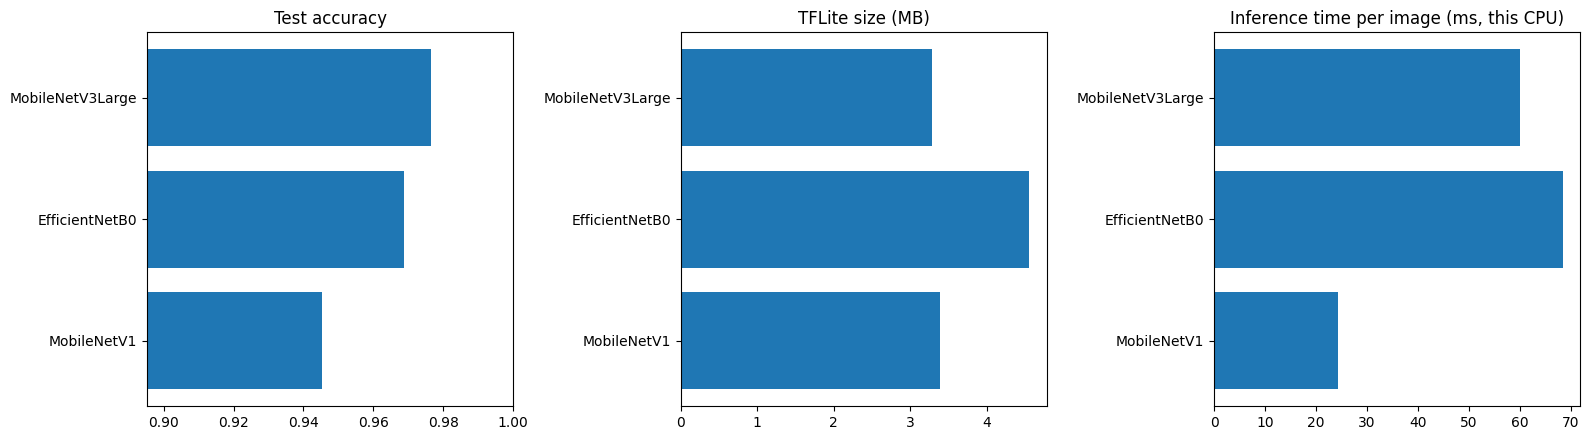

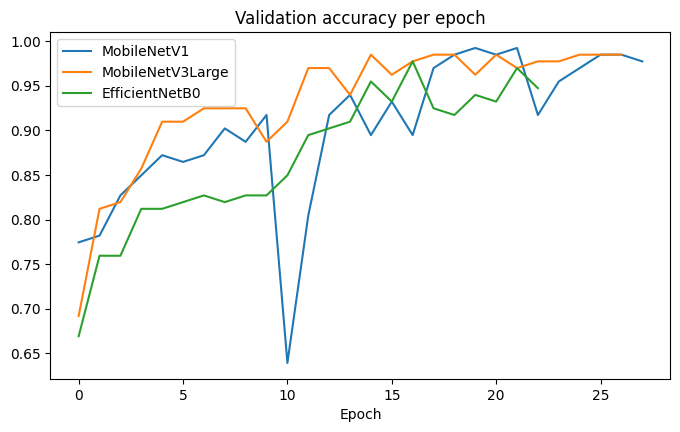

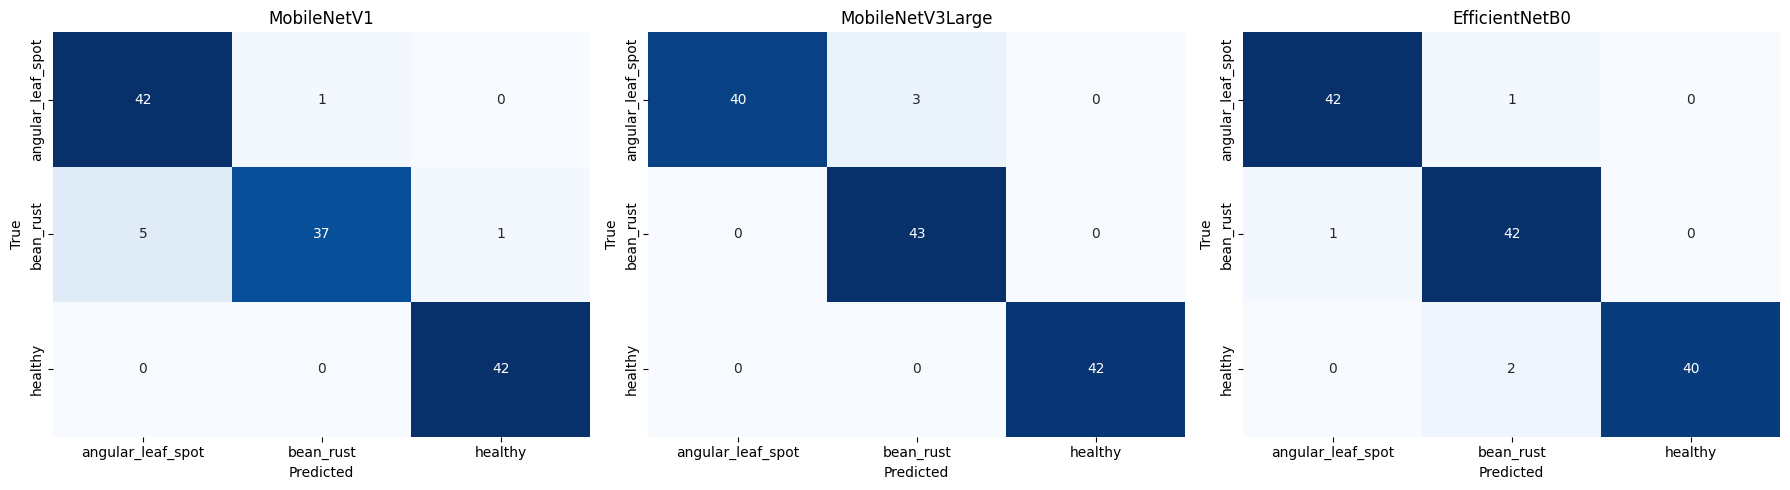

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
names = df.index.tolist()
ax[0].barh(names, df["test acc"]); ax[0].set_title("Test accuracy"); ax[0].set_xlim(max(0, df["test acc"].min() - 0.05), 1)
ax[1].barh(names, df["TFLite size (MB)"]); ax[1].set_title("TFLite size (MB)")
ax[2].barh(names, df["ms / image (this CPU)"]); ax[2].set_title("Inference time per image (ms, this CPU)")
for a in ax:
    a.invert_yaxis()
plt.tight_layout(); plt.show()

# Validation accuracy curves
plt.figure(figsize=(8, 4.5))
for name, (hist, n_head) in histories.items():
    plt.plot(hist["val_accuracy"], label=name)
plt.title("Validation accuracy per epoch"); plt.xlabel("Epoch"); plt.legend(); plt.show()

# Confusion matrices side by side
fig, ax = plt.subplots(1, len(conf_mats), figsize=(6 * len(conf_mats), 5))
for a, (name, cm) in zip(np.atleast_1d(ax), conf_mats.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=a)
    a.set_title(name); a.set_xlabel("Predicted"); a.set_ylabel("True")
plt.tight_layout(); plt.show()

### Picking a model for the app
- The test set has only 128 images, so **each mistake is about 0.8%**. Compare the `errors` column: 2 vs 3 mistakes is not a real difference.
- If accuracy is about the same, choose the **smaller and faster** model, because many farmers have low-end phones.
- Check that `TFLite acc` is close to `test acc` for the model you pick.

The next cell copies the model you choose to `export/bean_model.tflite`, the file the Android app uses.

In [21]:
import shutil

CHOSEN = df.index[0]          # best test accuracy; or set by hand, e.g. "MobileNetV3Large"
shutil.copy(os.path.join(CMP_DIR, f"{CHOSEN}.tflite"), os.path.join(OUT_DIR, "bean_model.tflite"))
with open(os.path.join(OUT_DIR, "labels.txt"), "w") as f:
    f.write("\n".join(class_names))
print(f"Copied {CHOSEN} -> {OUT_DIR}/bean_model.tflite")

Copied MobileNetV3Large -> export/bean_model.tflite
